# 第 1 课 · 用二元 Logit 估计需求

一家商店想知道，如果同一种商品的价格从 8 元涨到 9 元，购买率会变化多少。我们用模拟的随机定价数据估计消费者的选择模型，再用估计结果回答这个问题。

**建议用时 50 分钟。** 先逐格运行，再做练习。你需要了解概率、对数和基本的 Python 数组操作。

1. 从效用差写出购买概率。
2. 用极大似然估计购买意愿和价格系数。
3. 比较估计参数与模拟真值，计算提价的反事实购买率。

## 1. 从效用到购买概率

每位消费者看到一个报价 $p_i$，选择购买（$y_i=1$）或不购买（$y_i=0$）。购买相对于不购买的效用差为

$$
\Delta U_i = \alpha + \beta(p_i-8) + \varepsilon_i,
\qquad y_i = \mathbf{1}[\Delta U_i\ge 0].
$$

$\alpha$ 是价格为 8 元时的系统性效用差，$\beta$ 是价格每增加 1 元时系统性效用差的变化。我们假设 $\varepsilon_i$ 相互独立，服从标准 Logistic 分布，与报价独立。规定误差的尺度后，两个参数都以该尺度下的效用单位来解释。

标准 Logistic 分布的分布函数是 $\Lambda(z)=1/(1+e^{-z})$。利用分布的对称性，二元 Logit 模型（binary logit）的购买概率是

$$
q_i \equiv \Pr(y_i=1\mid p_i)
= \Pr\big(\varepsilon_i \ge -[\alpha+\beta(p_i-8)]\big)
= \Lambda\big(\alpha+\beta(p_i-8)\big).
$$

如果 $\beta<0$，随着价格上升，购买概率怎样变化？

## 2. 模拟随机定价

给 2,000 位消费者分别从 5 到 11 元的整数价中等概率随机抽取一个报价，另行抽取每人的效用冲击。设真实参数为 $\alpha=0.60$ 和 $\beta=-0.55$。模拟者知道真值，接下来的估计只使用看到的报价和购买决策。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from scipy.special import expit

rng = np.random.default_rng(120)
sample_size = 2_000
reference_price = 8.0
price_levels = np.arange(5, 12)
true_intercept, true_price_coefficient = 0.60, -0.55

price = rng.choice(price_levels, size=sample_size)
utility_shock = rng.logistic(size=sample_size)
price_distance = price - reference_price
utility_difference = (
    true_intercept + true_price_coefficient * price_distance + utility_shock
)
purchased = (utility_difference >= 0).astype(int)

print(f"样本人数 {sample_size:,}，样本购买率 {purchased.mean():.1%}")
print("报价（元）  是否购买")
for observed_price, decision in zip(price[:6], purchased[:6]):
    print(f"{observed_price:>8}  {decision:>8}")

样本人数 2,000，样本购买率 63.6%
报价（元）  是否购买
       7         0
      10         0
       6         1
       5         1
       9         1
       6         1


## 3. 用购买记录估计参数

买家为似然贡献 $q_i$，未购买者贡献 $1-q_i$。给定报价，各人的决策独立。把各人的概率相乘得到样本似然，取对数后得到

$$
\ell(\alpha,\beta)
= \sum_i \Big[y_i\log q_i + (1-y_i)\log(1-q_i)\Big].
$$

极大似然估计（maximum likelihood estimation, MLE）选择使样本似然最大的参数。下面用 SciPy 最小化负的平均对数似然。对每人令 $z_i=\alpha+\beta(p_i-8)$，其负对数似然可写成 $\log(1+e^{(1-2y_i)z_i})$。用 `np.logaddexp` 可避免直接取 `log(0)` 或因指数项过大而溢出。

In [2]:
def negative_mean_log_likelihood(parameters):
    intercept, price_coefficient = parameters
    index = intercept + price_coefficient * price_distance
    return np.logaddexp(0.0, (1 - 2 * purchased) * index).mean()


def likelihood_gradient(parameters):
    intercept, price_coefficient = parameters
    index = intercept + price_coefficient * price_distance
    residual = expit(index) - purchased
    return np.array([residual.mean(), (residual * price_distance).mean()])


initial_parameters = np.array([0.0, 0.0])
fit = minimize(
    negative_mean_log_likelihood,
    x0=initial_parameters,
    jac=likelihood_gradient,
    method="BFGS",
    options={"gtol": 1e-7},
)
if not fit.success:
    raise RuntimeError(f"估计未收敛：{fit.message}")

estimated_intercept, estimated_price_coefficient = fit.x

print(f"负平均对数似然 {negative_mean_log_likelihood(initial_parameters):.4f} → {fit.fun:.4f}")
print(f"梯度中最大绝对值 {np.max(np.abs(fit.jac)):.2e}")
print()
print("参数               模拟真值    估计值")
print(f"效用截距 α        {true_intercept:>8.3f}  {estimated_intercept:>8.3f}")
print(f"价格系数 β        {true_price_coefficient:>8.3f}  {estimated_price_coefficient:>8.3f}")

负平均对数似然 0.6931 → 0.5343
梯度中最大绝对值 3.65e-09

参数               模拟真值    估计值
效用截距 α           0.600     0.676
价格系数 β          -0.550    -0.582


零初值给每个人 50% 的购买概率。估计后，负平均对数似然下降，梯度接近零。估计参数通常和真值有差别，因为购买记录受有限样本中随机报价和效用冲击的影响。

下面把每个报价对应的样本购买率画成点，再画出模型的拟合曲线。曲线上的每个位置表示，如果该人群面对横轴标出的同一价格，模型预测的购买概率。

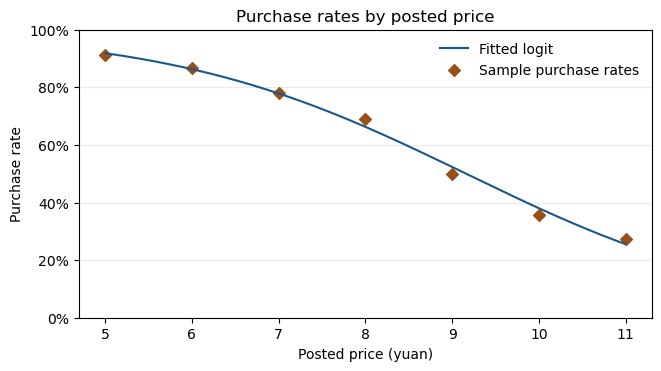

In [3]:
def predict_purchase_rate(offer_price):
    index = estimated_intercept + estimated_price_coefficient * (offer_price - reference_price)
    return expit(index)


observed_rates = [purchased[price == level].mean() for level in price_levels]
price_grid = np.linspace(price_levels.min(), price_levels.max(), 150)

fig, ax = plt.subplots(figsize=(6.5, 3.6), layout="constrained")
ax.plot(price_grid, predict_purchase_rate(price_grid), color="#18588a", label="Fitted logit")
ax.scatter(price_levels, observed_rates, color="#9a4f18", marker="D", label="Sample purchase rates")
ax.set(
    title="Purchase rates by posted price",
    xlabel="Posted price (yuan)",
    ylabel="Purchase rate",
    xticks=price_levels,
    ylim=(0, 1),
)
ax.yaxis.set_major_formatter("{x:.0%}")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.show()

## 4. 计算提价的反事实

在同一人群中比较两种情景。第一种给每个人报 8 元，第二种给每个人报 9 元。在模型里，只改变价格，保持偏好参数和效用冲击的分布不变。两个报价都在随机定价的范围内。

In [4]:
baseline_price, higher_price = 8.0, 9.0
baseline_rate = predict_purchase_rate(baseline_price)
higher_price_rate = predict_purchase_rate(higher_price)
change_pp = 100 * (higher_price_rate - baseline_rate)
true_change_pp = 100 * (
    expit(true_intercept + true_price_coefficient * (higher_price - reference_price))
    - expit(true_intercept + true_price_coefficient * (baseline_price - reference_price))
)

print(f"统一报价 {baseline_price:.0f} 元时的模型购买率 {baseline_rate:.1%}")
print(f"统一报价 {higher_price:.0f} 元时的模型购买率 {higher_price_rate:.1%}")
print(f"提价的反事实变化 {change_pp:+.1f} 个百分点")
print(f"由模拟真值算出的变化 {true_change_pp:+.1f} 个百分点")

统一报价 8 元时的模型购买率 66.3%
统一报价 9 元时的模型购买率 52.3%
提价的反事实变化 -13.9 个百分点
由模拟真值算出的变化 -13.3 个百分点


差值以百分点计，用四舍五入前的预测值计算。同一个价格系数会在不同起点上产生不同的百分点变化，因为 Logit 购买概率随价格的变化是非线性的。真实数据中，若商店根据未观测到的购买意愿定价，解释价格系数与模拟提价都需要重新论证报价的外生性或采用其他识别策略。

## 动手练习

1. **比较两个提价起点。** 分别计算从 6 元涨到 7 元和从 8 元涨到 9 元时的购买率变化。哪一组的百分点变化更大？联系曲线的斜率解释。
2. **观察抽样波动。** 把样本量改成 200，选三个随机种子重新执行整份 Notebook，记录价格系数，再用 2,000 人重复。比较两组的估计值与真值。为什么单次结果不能证明样本量越大，估计一定越接近真值？
3. **判断外生性。** 假设商店知道每位消费者本期的效用冲击，并只给冲击较高的人报高价。这个报价规则破坏了本课的哪项条件？为什么即使样本非常大，也可能把不同消费者的购买意愿误读为价格效应？